# 🔬 Laboratorio HOE para HUD

Simulación para **jugar** con un elemento óptico holográfico (HOE) en el parabrisas: grabarlo, iluminarlo, ver sus rayos y ver la imagen que percibe el conductor.

**Cómo usarlo.** Corre las celdas en orden (`Shift + Enter`). Cada laboratorio tiene tres partes:
1. la **función** con la física (léela, está comentada línea por línea),
2. una **llamada de ejemplo** que puedes copiar y modificar,
3. **controles deslizables** para jugar.

**Instalación**
```
pip install numpy scipy matplotlib ipywidgets
pip install cupy-cuda12x                 # opcional: GPU NVIDIA con CUDA 12 (Lab 3)
conda install -c conda-forge holopy      # opcional: HoloPy (Lab 3)
```
⚠️ `pip install holopy` instala **otro paquete** que no tiene nada que ver. El HoloPy de Manoharan Lab se instala con conda.

**Qué modelo usa**
- **Rayos** con la regla de la rejilla (Labs 1 y 2): dice *a dónde* va la luz → aberraciones, distorsión, posición de la imagen.
- **Eficiencia de Bragg** de Kogelnik: dice *cuánta* luz difracta el holograma de volumen → brillo.
- **Ondas** por espectro angular (Lab 3, el mismo método de `holopy.propagate`): dice qué tan pequeña puede ser la mancha (difracción).

## Mapa de la simulación

```
 DISEÑO (tú decides)          λ de grabación · onda de referencia R · punto de imagen O · película
        │
        ▼
 1. GRABAR     HOE(...)            R y O interfieren → franjas → vector de red  K = k_O − k_R
        │                          (en el plano del vidrio: K∥ = ∇φ_H, la Ec. 1 del reporte)
        ▼
 2. FABRICAR   hoe.contraccion_*   el autoclave encoge la película → K cambia
        │
        ▼
 3. ILUMINAR   proyector = {...}   λ de lectura · ángulo · colimado o a cierta distancia
        │
        ├──► Lab 1   difractar()            k_sal∥ = k_ent∥ + K∥        → diagrama de rayos
        ├──► Lab 2   ver_como_conductor()   rayos ojo → HOE → proyector  → imagen percibida
        └──► Lab 3   propagar()             espectro angular            → enfoque con ondas
                      │
                      ▼ eficiencia_bragg()   ¿se cumple Bragg?  → brillo de cada rayo
 4. OBSERVAR   ojo = {...}         posición · pupila · a qué distancia enfoca
```

**Coordenadas** (como la Figura 3 del reporte): el HOE está en el plano `z = 0`; `z < 0` es dentro del auto (ojo en `z = −0.8 m`), `z > 0` es afuera (imagen virtual en `z = +1.2 m`). `y` es vertical (arriba +) y `x` horizontal. Todo en metros.

## 0. Preparación

In [3]:
import copy, time
import numpy as np
import scipy.fft as sfft
import matplotlib.pyplot as plt
from scipy.ndimage import map_coordinates
import ipywidgets as w
from ipywidgets import interact, interact_manual

# Estilo de gráficas (colores de una paleta probada para daltonismo)
TINTA, TINTA2, REJILLA, FONDO = '#0b0b0b', '#52514e', '#e4e3df', '#fcfcfb'
AZUL, NARANJA, AQUA = '#2a78d6', '#eb6834', '#1baf7a'
plt.rcParams.update({
    'figure.facecolor': FONDO, 'axes.facecolor': FONDO, 'savefig.facecolor': FONDO,
    'axes.edgecolor': TINTA2, 'axes.labelcolor': TINTA2, 'xtick.color': TINTA2, 'ytick.color': TINTA2,
    'axes.spines.top': False, 'axes.spines.right': False, 'font.size': 10, 'legend.frameon': False,
})
ESTILO = {'description_width': '170px'}     # para que se lean las etiquetas de los controles

# Geometría del reto
Z_OJO    = -0.80   # m: ojo del conductor
Z_IMAGEN = +1.20   # m: imagen virtual deseada, detrás del vidrio  →  2.0 m del ojo

## 1. Las ondas: ¿de dónde viene la luz?

Usamos dos tipos de onda:
- **Onda plana** (`fuente_plana`): todos los rayos van en la misma dirección. Así es un proyector *colimado* o un láser expandido.
- **Onda esférica** (`fuente_puntual`): los rayos salen de un punto. Así es la onda objeto `O` (sale del punto donde queremos la imagen) o un proyector cercano.

Para un rayo que viaja en la dirección unitaria `u`, el vector de onda es `k = (2π n / λ) · u`.

**Snell en una línea:** al cruzar una frontera plana (aire → vidrio → PVB) la parte de `k` paralela a la frontera, `k∥ = (kx, ky)`, **no cambia**; solo se ajusta `kz` para que `|k| = 2πn/λ`. Por eso en este modelo el vidrio plano no cambia las direcciones de salida: lo que importa es `k∥`.

In [4]:
def fuente_plana(theta_deg, phi_deg=0.0):
    '''Onda plana que sube con ángulo theta (vertical) y phi (horizontal) respecto a la normal del vidrio.'''
    t, p = np.radians(theta_deg), np.radians(phi_deg)
    return {'tipo': 'plana', 'dir': np.array([np.sin(p), np.sin(t) * np.cos(p), np.cos(t) * np.cos(p)])}


def fuente_puntual(x, y, z):
    '''Onda esférica que sale del punto (x, y, z).'''
    return {'tipo': 'punto', 'pos': np.array([x, y, z], dtype=float)}


def direccion(fuente, P):
    '''Dirección unitaria en la que viaja la luz de 'fuente' al pasar por los puntos P (arreglo [..., 3]).'''
    if fuente['tipo'] == 'plana':
        return np.broadcast_to(fuente['dir'], P.shape)
    v = P - fuente['pos']                                  # del punto fuente hacia P
    return v / np.linalg.norm(v, axis=-1, keepdims=True)


def vector_k(u, lam, n=1.0):
    '''Vector de onda dentro de un medio de índice n para un rayo que en aire viaja en dirección u.
    Snell: kx, ky se conservan; kz se ajusta (mismo signo que u_z).'''
    k0 = 2 * np.pi / lam
    kxy = k0 * u[..., :2]
    kz = np.sign(u[..., 2]) * np.sqrt((n * k0)**2 - np.sum(kxy**2, axis=-1))
    return np.concatenate([kxy, kz[..., None]], axis=-1)

## 2. Grabar el HOE: todo se resume en el vector de red **K**

Al grabar, la onda de referencia `R` y la onda objeto `O` interfieren dentro de la película y dejan franjas. Las franjas en cada punto quedan descritas por un vector:

$$\mathbf K = \mathbf k_O - \mathbf k_R$$

- Su parte en el plano, `K∥`, es el gradiente de la fase grabada, $\nabla\varphi_H$ con $\varphi_H = \varphi_O - \varphi_R$ (la Ec. 1 de su reporte). **Decide a dónde va la luz.**
- Su parte en `z`, `Kz`, es la inclinación de las franjas dentro del volumen. **Decide cuánta luz se difracta** (Bragg).
- El periodo de las franjas es `2π/|K|`.

Como `K` cambia de punto a punto (porque `O` es esférica), el HOE es una rejilla "variable": eso lo convierte en lente.

**Contracción.** Si en el autoclave la película se encoge un factor `s`, las franjas se juntan: `K` crece como `1/(1−s)` y además cada franja se mueve hacia el centro.

In [5]:
class HOE:
    def __init__(self, lam, referencia, objeto, ancho=0.12, alto=0.08, n=1.5, espesor=16e-6, dn=0.025):
        self.lam = lam                  # λ con la que se GRABÓ
        self.R = referencia             # onda de referencia (dirección del futuro proyector)
        self.O = objeto                 # onda objeto (sale del punto de la imagen deseada)
        self.ancho, self.alto = ancho, alto      # tamaño del HOE [m]
        self.n = n                      # índice medio de la película
        self.espesor = espesor          # espesor de la película [m]
        self.dn = dn                    # modulación del índice (qué tan "fuertes" son las franjas)
        self.contraccion_plano = 0.0    # fracción: 0.01 = se encogió 1 % a lo ancho
        self.contraccion_espesor = 0.0  # fracción: 0.01 = se encogió 1 % de grueso

    def K(self, P):
        '''Vector de red (dentro de la película) en los puntos P [..., 3] del HOE.'''
        s, sz = self.contraccion_plano, self.contraccion_espesor
        P0 = np.array(P, dtype=float, copy=True)
        P0[..., :2] /= (1 - s)                       # dónde estaba esa franja al grabar
        kO = vector_k(direccion(self.O, P0), self.lam, self.n)
        kR = vector_k(direccion(self.R, P0), self.lam, self.n)
        K = kO - kR
        K[..., :2] /= (1 - s)                        # franjas más juntas a lo ancho
        K[..., 2] /= (1 - sz)                        # franjas más juntas a lo grueso
        return K

    def dentro(self, P):
        '''True donde el punto cae sobre el HOE.'''
        return (np.abs(P[..., 0]) <= self.ancho / 2) & (np.abs(P[..., 1]) <= self.alto / 2)

In [6]:
# ---------- EL DISEÑO (cámbialo para "meter" tu propio HOE) ----------
LAMBDA_GRAB = 532e-9
hoe = HOE(lam=LAMBDA_GRAB,
          referencia=fuente_plana(45),                 # el proyector llegará colimado a 45°
          objeto=fuente_puntual(0, 0, Z_IMAGEN))       # queremos la imagen 1.2 m detrás del vidrio

# Mira el vector de red en dos puntos del HOE
for nombre, P in [('centro', [0, 0, 0]), ('4 cm arriba', [0, 0.04, 0])]:
    K = hoe.K(np.array(P, dtype=float))
    print(f"{nombre:12s} K = {np.round(K / 1e6, 3)} rad/µm  → franjas cada "
          f"{2 * np.pi / np.hypot(K[0], K[1]) * 1e9:.0f} nm en el plano y "
          f"{2 * np.pi / np.linalg.norm(K) * 1e9:.0f} nm en el volumen")

centro       K = [  0.     -8.351 -33.34 ] rad/µm  → franjas cada 752 nm en el plano y 183 nm en el volumen
4 cm arriba  K = [  0.     -7.958 -33.335] rad/µm  → franjas cada 790 nm en el plano y 183 nm en el volumen


## 3. Iluminar el HOE: la regla de la rejilla y la condición de Bragg

**A dónde va la luz** (holograma delgado). Un rayo que llega con `k_ent` sale con:

$$\mathbf k_{sal,\parallel} = \mathbf k_{ent,\parallel} + \mathbf K_\parallel ,\qquad |\mathbf k_{sal}| = \frac{2\pi}{\lambda_{lectura}}$$

y como es un HOE de **reflexión**, sale hacia el conductor (`kz < 0`). Si iluminas exactamente con `R`, sale exactamente `O`: la imagen queda perfecta. Cualquier diferencia (otra λ, otro ángulo, contracción) cambia `k_sal` → **aberraciones**.

`difractar_inverso` hace lo mismo al revés: dado el rayo que sale hacia el ojo, dice de dónde tuvo que venir.

**Cuánta luz** (holograma de volumen, Kogelnik 1969). Se calcula el desfase de Bragg

$$\vartheta = \frac{\beta^2 - |\mathbf k_{ent} + \mathbf K|^2}{2\beta},\qquad \beta = \frac{2\pi n}{\lambda}$$

(`ϑ = 0` es Bragg perfecto) y con él la eficiencia de una rejilla de reflexión:

$$\eta = \frac{1}{1 + \left(\dfrac{r}{\nu\,\sinh r}\right)^2},\quad r = \sqrt{\nu^2 - \xi^2},\quad \nu = \frac{\pi\,\Delta n\, d}{\lambda\sqrt{|c_R c_S|}},\quad \xi = \frac{\vartheta\, d}{2|c_S|}$$

(polarización s; `c_R` y `c_S` son los cosenos directores en z de los haces incidente y difractado).

In [7]:
def difractar(P, u_in, hoe, lam):
    '''Rayo que llega en dirección u_in al punto P del HOE → dirección del rayo difractado (hacia el conductor).'''
    k0 = 2 * np.pi / lam
    uxy = (k0 * u_in[..., :2] + hoe.K(P)[..., :2]) / k0          # k_sal∥ = k_ent∥ + K∥
    s2 = np.sum(uxy**2, axis=-1)
    uz = -np.sqrt(np.where(s2 < 1, 1 - s2, np.nan))               # reflexión: sale con z negativo
    return np.concatenate([uxy, uz[..., None]], axis=-1)          # NaN = no hay rayo (evanescente)


def difractar_inverso(P, u_sal, hoe, lam):
    '''Rayo que SALE del punto P hacia el ojo en dirección u_sal → de dónde tuvo que llegar.'''
    k0 = 2 * np.pi / lam
    uxy = (k0 * u_sal[..., :2] - hoe.K(P)[..., :2]) / k0          # k_ent∥ = k_sal∥ − K∥
    s2 = np.sum(uxy**2, axis=-1)
    uz = np.sqrt(np.where(s2 < 1, 1 - s2, np.nan))                # llegaba desde el lado del conductor
    return np.concatenate([uxy, uz[..., None]], axis=-1)


def eficiencia_bragg(P, u_in, hoe, lam):
    '''Fracción de la luz que el holograma de volumen difracta (Kogelnik, rejilla de reflexión, pol. s).'''
    beta = 2 * np.pi * hoe.n / lam
    ki = vector_k(u_in, lam, hoe.n)                     # rayo incidente dentro de la película
    sigma = ki + hoe.K(P)                               # lo que la red "quiere" difractar
    desfase = (beta**2 - np.sum(sigma**2, axis=-1)) / (2 * beta)     # ϑ
    cR, cS = ki[..., 2] / beta, sigma[..., 2] / beta    # cS < 0 en reflexión
    d = hoe.espesor * (1 - hoe.contraccion_espesor)
    nu = np.pi * hoe.dn * d / (lam * np.sqrt(np.abs(cR * cS)))
    xi = desfase * d / (2 * np.abs(cS))
    r = np.sqrt(nu**2 - xi**2 + 0j)                     # real o imaginario, ambos valen
    with np.errstate(divide='ignore', invalid='ignore'):
        r_sinh = np.where(np.abs(r) < 1e-9, 1.0, r / np.sinh(r))
    eta = 1 / (1 + np.abs(r_sinh / nu)**2)
    return np.nan_to_num(np.where(cS < 0, eta, 0.0))

In [8]:
# Mini experimento: un rayo del proyector pega en el centro del HOE
P = np.array([0.0, 0.0, 0.0])
u_in = direccion(fuente_plana(45), P)
print('sale en dirección', np.round(difractar(P, u_in, hoe, 532e-9), 4), ' ← directo al ojo')
for lam in [532e-9, 537e-9, 545e-9, 633e-9]:
    print(f'leyendo con λ = {lam * 1e9:.0f} nm → eficiencia de Bragg {eficiencia_bragg(P, u_in, hoe, lam):.2f}')

sale en dirección [ 0.  0. -1.]  ← directo al ojo
leyendo con λ = 532 nm → eficiencia de Bragg 0.97
leyendo con λ = 537 nm → eficiencia de Bragg 0.86
leyendo con λ = 545 nm → eficiencia de Bragg 0.04
leyendo con λ = 633 nm → eficiencia de Bragg 0.00


## 4. El proyector (PGU)

El proyector apunta al HOE con un ángulo `theta`. Dos modelos:
- **Colimado** (`distancia=None`): cada píxel sale como una onda plana con su propia dirección. Es lo que pide el reto ("iluminado desde una dirección").
- **A cierta distancia** (`distancia=0.4`, en metros): cada píxel es un punto que emite luz.

`fov` es el campo de visión del proyector en grados (horizontal, vertical). Los signos `SX, SY` voltean la imagen para que el conductor la vea derecha. Un HUD real también manda la imagen "espejeada" al proyector.

In [9]:
PROYECTOR = dict(theta=45, distancia=None, fov=(12, 6))      # el de diseño
SX, SY = -1, +1                                              # orientación de la imagen


def ejes_proyector(proyector):
    '''Eje del proyector y sus direcciones "derecha" (ex) y "arriba" (ey).'''
    t = np.radians(proyector['theta'])
    eje = np.array([0.0, np.sin(t), np.cos(t)])
    return eje, np.array([1.0, 0.0, 0.0]), np.array([0.0, np.cos(t), -np.sin(t)])


def direccion_proyector(proyector, P):
    '''Dirección de la luz del píxel CENTRAL del proyector al llegar a los puntos P.'''
    eje, _, _ = ejes_proyector(proyector)
    if proyector['distancia'] is None:
        return np.broadcast_to(eje, P.shape)
    v = P + proyector['distancia'] * eje                     # P − posición del proyector
    return v / np.linalg.norm(v, axis=-1, keepdims=True)


def pixel_del_proyector(P, u_in, proyector, forma):
    '''Qué píxel (fila, columna) del proyector manda un rayo que llega a P con dirección u_in.'''
    alto_img, ancho_img = forma
    eje, ex, ey = ejes_proyector(proyector)
    fx, fy = np.radians(proyector['fov'][0]), np.radians(proyector['fov'][1])
    if proyector['distancia'] is None:                       # colimado: píxel ↔ dirección
        cx = np.arctan2(u_in @ ex, u_in @ eje) / fx
        cy = np.arctan2(u_in @ ey, u_in @ eje) / fy
    else:                                                    # puntual: píxel ↔ punto en su pantalla
        L = proyector['distancia']
        C = -L * eje                                         # centro de la pantalla
        s = ((P - C) @ eje) / (u_in @ eje)
        S = P - s[..., None] * u_in                          # de qué punto de la pantalla salió
        cx = -((S - C) @ ex) / (2 * L * np.tan(fx / 2))
        cy = -((S - C) @ ey) / (2 * L * np.tan(fy / 2))
    return (0.5 + SY * cy) * (alto_img - 1), (0.5 + SX * cx) * (ancho_img - 1)

## 🔬 Lab 1 — Diagrama de rayos: el HOE como lente

Se lanzan rayos del proyector a lo largo del HOE, se difractan con `difractar()` y se dibujan:
- **Arriba:** vista lateral. Naranja = luz del proyector; color de la λ = luz que va al conductor (más tenue = menos eficiencia de Bragg); gris punteado = prolongación hacia atrás, de donde el ojo "cree" que viene la luz.
- **Abajo izquierda:** zoom donde se cruzan las prolongaciones. Azul = rayos de un abanico vertical; naranja = abanico horizontal. Si todos se cruzan en un punto, la imagen es perfecta.
- **Abajo derecha:** dónde cae cada rayo (de una malla de 15 × 15 sobre el HOE) en el plano de la imagen deseada.

**Qué probar** (sin respuestas, descúbrelas):
1. Lee con 540 nm. ¿Los rayos se siguen cruzando en un solo punto? ¿Los dos abanicos se cruzan en el mismo lugar?
2. Pon el proyector a 0.4 m en vez de colimado. ¿Dónde aparece ahora la imagen?
3. Contracción de 1 % en el plano y luego 1 % en el espesor. ¿Cuál mueve la imagen y cuál solo la apaga?
4. Sube el ángulo de lectura a 50°. ¿Qué cambia y qué no?

In [10]:
def trazar_abanico(hoe, lam, proyector, eje='y', n=13):
    '''n rayos del proyector que pegan en una línea vertical (eje='y') u horizontal (eje='x') del HOE.'''
    s = np.linspace(-1, 1, n)
    P = np.zeros((n, 3))
    if eje == 'y':
        P[:, 1] = s * hoe.alto / 2
    else:
        P[:, 0] = s * hoe.ancho / 2
    u_in = np.array(direccion_proyector(proyector, P))
    return P, u_in, difractar(P, u_in, hoe, lam), eficiencia_bragg(P, u_in, hoe, lam)


def cruce_con_rayo_central(P, u, i):
    '''z donde la prolongación de cada rayo cruza la del rayo central (componente i = 0 para x, 1 para y).'''
    c = len(P) // 2
    pend = u[:, i] / u[:, 2]
    with np.errstate(divide='ignore', invalid='ignore'):
        z = -(P[:, i] - P[c, i]) / (pend - pend[c])
    z[c] = np.nan
    return z


def dibujar_rayos(hoe, lam, proyector, n=13, guardar=None):
    eje_p, _, _ = ejes_proyector(proyector)
    Pt, uin_t, uout_t, eta_t = trazar_abanico(hoe, lam, proyector, 'y', n)
    Ps, uin_s, uout_s, eta_s = trazar_abanico(hoe, lam, proyector, 'x', n)
    luz = color_de_lambda(lam) * 0.85
    fig = plt.figure(figsize=(12, 8.4))
    gs = fig.add_gridspec(2, 2, height_ratios=[1.25, 1], width_ratios=[1.6, 1])

    # --- vista lateral ---
    a = fig.add_subplot(gs[0, :])
    z_atras = Z_IMAGEN + 0.45
    for P, uo, e in zip(Pt, uout_t, eta_t):
        ini = -proyector['distancia'] * eje_p if proyector['distancia'] else P - 0.5 * eje_p
        a.plot([ini[2], P[2]], [ini[1], P[1]], color=NARANJA, lw=1, alpha=0.6)
        if not np.isfinite(uo[2]):
            continue
        t = (Z_OJO - 0.08 - P[2]) / uo[2]                       # hasta pasar al ojo
        a.plot([P[2], P[2] + t * uo[2]], [P[1], P[1] + t * uo[1]], color=luz, lw=1.6, alpha=0.2 + 0.8 * e)
        t = (z_atras - P[2]) / uo[2]                            # prolongación hacia atrás
        a.plot([P[2], P[2] + t * uo[2]], [P[1], P[1] + t * uo[1]], color=TINTA2, lw=0.8, ls=(0, (3, 3)), alpha=0.6)
    a.add_patch(plt.Rectangle((-0.012, -hoe.alto / 2 - 0.02), 0.024, hoe.alto + 0.04, color='#b7d3f6', alpha=0.6, lw=0))
    a.plot([0, 0], [-hoe.alto / 2, hoe.alto / 2], color=AZUL, lw=3)
    a.text(0.025, -hoe.alto / 2 - 0.05, 'HOE en el vidrio\n(grosor exagerado)', fontsize=8, color=TINTA2, va='top')
    a.add_patch(plt.Circle((Z_OJO, 0), 0.025, fill=False, color=TINTA, lw=1.5))
    a.text(Z_OJO, -0.06, 'ojo', ha='center', fontsize=9)
    a.plot(Z_IMAGEN, 0, marker='*', ms=14, color=TINTA)
    a.text(Z_IMAGEN, 0.035, 'imagen deseada', ha='center', fontsize=9)
    if proyector['distancia']:
        C = -proyector['distancia'] * eje_p
        a.plot(C[2], C[1], 's', ms=9, color=NARANJA)
        a.text(C[2], C[1] - 0.05, 'proyector', ha='center', fontsize=9, color=NARANJA)
    else:
        a.text(-0.5 * eje_p[2], -0.5 * eje_p[1] - hoe.alto / 2 - 0.06, 'proyector colimado', ha='center', fontsize=9, color=NARANJA)
    a.set_aspect('equal')
    a.set_xlim(Z_OJO - 0.15, z_atras)
    a.set_xlabel('z [m]   (← dentro del auto  |  afuera →)')
    a.set_ylabel('y [m]')
    a.set_title(f'Vista lateral · λ lectura = {lam * 1e9:.0f} nm · punteado: de dónde "parece" venir la luz')

    # --- zoom donde se cruzan las prolongaciones ---
    b = fig.add_subplot(gs[1, 0])
    zc = np.concatenate([cruce_con_rayo_central(Pt, uout_t, 1), cruce_con_rayo_central(Ps, uout_s, 0), [Z_IMAGEN]])
    zc = zc[np.isfinite(zc)]
    margen = max(0.5 * (zc.max() - zc.min()), 0.03)
    zz = np.linspace(zc.min() - margen, zc.max() + margen, 50)
    for P, uo, i, color, nombre in [(Pt, uout_t, 1, AZUL, 'abanico vertical'), (Ps, uout_s, 0, NARANJA, 'abanico horizontal')]:
        c = len(P) // 2
        for j in range(len(P)):
            if np.isfinite(uo[j, 2]):
                off = (P[j, i] - P[c, i]) + zz * (uo[j, i] / uo[j, 2] - uo[c, i] / uo[c, 2])
                b.plot(zz, off * 1e3, color=color, lw=1, alpha=0.8, label=nombre if j == 0 else None)
    b.axvline(Z_IMAGEN, color=TINTA2, lw=1, ls=':')
    b.text(Z_IMAGEN, 0.98, ' deseada', transform=b.get_xaxis_transform(), fontsize=8, color=TINTA2, va='top')
    b.set_xlabel('z detrás del vidrio [m]')
    b.set_ylabel('distancia al rayo central [mm]')
    b.set_title('Zoom: ¿dónde se cruzan las prolongaciones?')
    b.grid(True, color=REJILLA)
    b.legend(fontsize=8, loc='upper left')

    # --- mancha en el plano de la imagen deseada ---
    c_ = fig.add_subplot(gs[1, 1])
    g = np.linspace(-1, 1, 15)
    GX, GY = np.meshgrid(g * hoe.ancho / 2, g * hoe.alto / 2)
    P2 = np.stack([GX.ravel(), GY.ravel(), np.zeros(GX.size)], axis=-1)
    ui2 = np.array(direccion_proyector(proyector, P2))
    uo2 = difractar(P2, ui2, hoe, lam)
    e2 = eficiencia_bragg(P2, ui2, hoe, lam)
    X = P2 + ((Z_IMAGEN - P2[:, 2]) / uo2[:, 2])[:, None] * uo2
    c_.scatter(X[:, 0] * 1e3, X[:, 1] * 1e3, s=12, c=e2, cmap='Greys', vmin=-0.3, vmax=1, edgecolors='none')
    c_.plot(0, 0, '+', color=AZUL, ms=12, mew=2)
    r = max(np.nanmax(np.abs(X[:, :2])) * 1e3 * 1.1, 0.05)      # mínimo ±0.05 mm
    c_.set_xlim(-r, r); c_.set_ylim(-r, r); c_.set_aspect('equal')
    c_.set_xlabel('x [mm]'); c_.set_ylabel('y [mm]')
    c_.set_title(f'Dónde cae cada rayo en z = {Z_IMAGEN:.2f} m\n(+ = imagen deseada · gris = poca eficiencia)', fontsize=10)
    c_.grid(True, color=REJILLA)
    fig.tight_layout()
    if guardar:
        fig.savefig(guardar, dpi=150, bbox_inches='tight')
    plt.show()


def color_de_lambda(lam):
    '''Color RGB aproximado de una longitud de onda visible (solo para pintar).'''
    nm = lam * 1e9
    if nm < 440:   rgb = (-(nm - 440) / 60, 0, 1)
    elif nm < 490: rgb = (0, (nm - 440) / 50, 1)
    elif nm < 510: rgb = (0, 1, -(nm - 510) / 20)
    elif nm < 580: rgb = ((nm - 510) / 70, 1, 0)
    elif nm < 645: rgb = (1, -(nm - 645) / 65, 0)
    else:          rgb = (1, 0, 0)
    return np.clip(rgb, 0, 1)

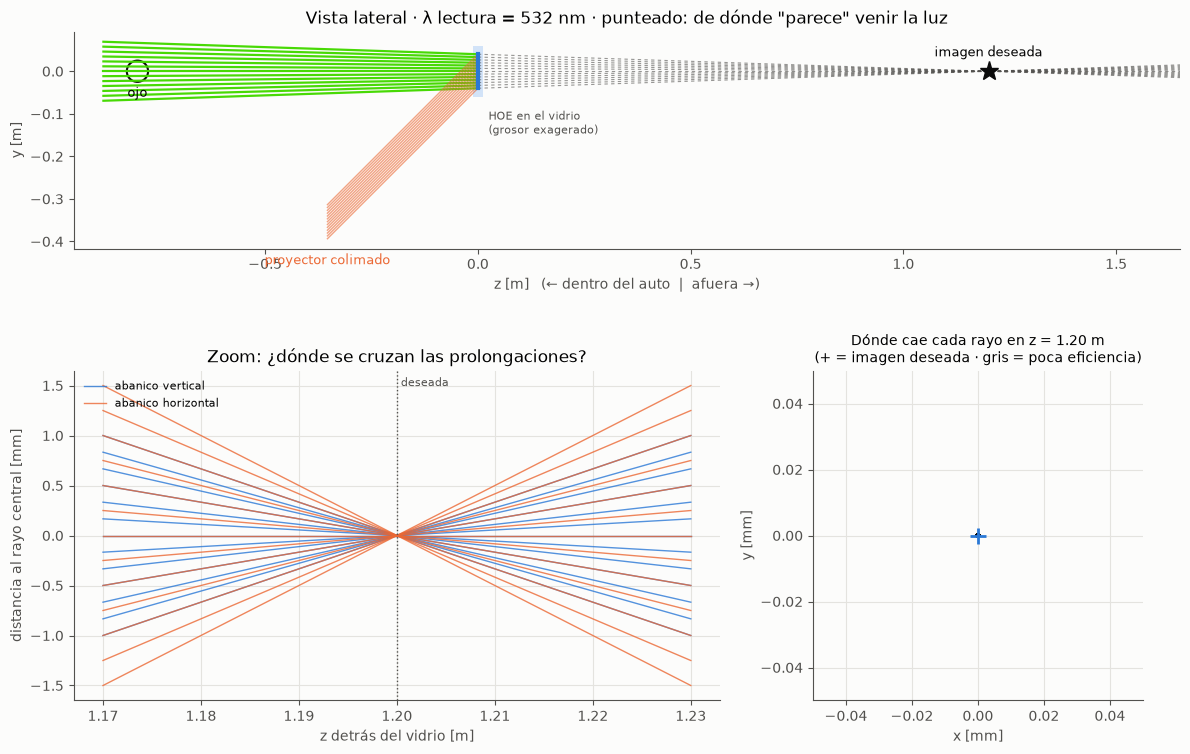

In [11]:
# Ejemplo: el diseño, leído exactamente como se grabó
dibujar_rayos(hoe, 532e-9, PROYECTOR)

In [ ]:
def lab_rayos(lambda_nm, angulo, colimado, distancia_m, contraccion_plano_pct, contraccion_espesor_pct):
    h = copy.copy(hoe)                                   # copia: no tocamos el diseño original
    h.contraccion_plano = contraccion_plano_pct / 100
    h.contraccion_espesor = contraccion_espesor_pct / 100
    proy = dict(theta=angulo, distancia=None if colimado else distancia_m, fov=PROYECTOR['fov'])
    dibujar_rayos(h, lambda_nm * 1e-9, proy)

interact(lab_rayos,
         lambda_nm=w.FloatSlider(value=532, min=450, max=680, step=1, description='λ lectura [nm]', style=ESTILO, continuous_update=False),
         angulo=w.FloatSlider(value=45, min=30, max=60, step=0.5, description='ángulo proyector [°]', style=ESTILO, continuous_update=False),
         colimado=w.Checkbox(value=True, description='proyector colimado'),
         distancia_m=w.FloatSlider(value=0.40, min=0.15, max=2.0, step=0.05, description='distancia proyector [m]', style=ESTILO, continuous_update=False),
         contraccion_plano_pct=w.FloatSlider(value=0, min=-2, max=2, step=0.1, description='contracción plano [%]', style=ESTILO, continuous_update=False),
         contraccion_espesor_pct=w.FloatSlider(value=0, min=0, max=4, step=0.1, description='contracción espesor [%]', style=ESTILO, continuous_update=False));

## 🔬 Lab 2 — Lo que ve el conductor

Seguir la luz desde el proyector es ineficiente: casi ningún rayo atina a la pupila. Por eso se traza **al revés** (como en los videojuegos):

1. Para cada dirección en la que mira el conductor y para cada punto de su pupila, se lanza un rayo hacia el punto que el ojo está enfocando.
2. Se ve dónde cruza el HOE y con `difractar_inverso()` se calcula de dónde tuvo que llegar la luz.
3. Con `pixel_del_proyector()` se averigua qué píxel de la imagen mandó esa luz, y se multiplica por la eficiencia de Bragg.
4. Se promedia sobre la pupila. Si los rayos de la pupila "ven" píxeles distintos, la imagen se ve borrosa.

El ojo es una lente ideal que enfoca a la distancia `enfoque`: un rayo se ve en el lugar donde su prolongación cruza ese plano.

**Qué probar:**
1. Usa la `rejilla`. ¿Las líneas horizontales son rectas? ¿Por qué la imagen se ve aplastada en vertical? (pista: 45°)
2. Lee con 545 nm, con y sin Bragg. ¿Qué parte del efecto es geometría y qué parte es brillo?
3. Proyector a 0.4 m: ¿a qué distancia tiene que enfocar el ojo para verla nítida?
4. Mueve el ojo 4 cm arriba o abajo. Haz la pupila de 2 mm (de día) y de 8 mm (de noche).
5. Pon el ojo en x = −3.2 cm y luego en x = +3.2 cm (izquierdo y derecho). ¿Ven lo mismo los dos ojos?

In [ ]:
def patron_pupila(diametro, anillos=3):
    '''Puntos repartidos en la pupila: centro + anillos de 6, 12, 18 puntos.'''
    pts = [(0.0, 0.0)]
    for a in range(1, anillos + 1):
        r = diametro / 2 * a / anillos
        ang = 2 * np.pi * np.arange(6 * a) / (6 * a)
        pts += list(zip(r * np.cos(ang), r * np.sin(ang)))
    return np.array(pts)


def ver_como_conductor(imagen, hoe, lam, proyector, ojo, fov=(10, 5), pix=(200, 100), bragg=True):
    '''Imagen que percibe el ojo. Regresa un arreglo (alto, ancho) con la intensidad vista en cada dirección.'''
    # 1) direcciones de mirada (ángulos) y punto que el ojo enfoca en cada una
    ax = np.radians(np.linspace(-fov[0] / 2, fov[0] / 2, pix[0]))
    ay = np.radians(np.linspace(fov[1] / 2, -fov[1] / 2, pix[1]))          # de arriba hacia abajo
    AX, AY = np.meshgrid(ax, ay)
    E = np.array([ojo.get('x', 0.0), ojo['y'], ojo['z']])                    # centro del ojo
    D = ojo['enfoque']
    Q = np.stack([E[0] + D * np.tan(AX), E[1] + D * np.tan(AY), np.full_like(AX, E[2] + D)], axis=-1)
    # 2) rayos desde cada punto de la pupila hacia Q → dónde cruzan el HOE (z = 0)
    pp = patron_pupila(ojo['pupila'])
    pup = E + np.column_stack([pp, np.zeros(len(pp))])                     # puntos de la pupila en 3D
    U = Q[:, :, None, :] - pup[None, None, :, :]                             # [alto, ancho, pupila, 3]
    U /= np.linalg.norm(U, axis=-1, keepdims=True)
    H = pup[None, None] + (-pup[None, None, :, 2] / U[..., 2])[..., None] * U
    # 3) del HOE al ojo la luz viaja en −U: ¿de dónde llegó?
    u_in = difractar_inverso(H, -U, hoe, lam)
    # 4) ¿qué píxel del proyector manda esa luz?
    fila, col = pixel_del_proyector(H, u_in, proyector, imagen.shape)
    fila, col = np.nan_to_num(fila, nan=-10.0), np.nan_to_num(col, nan=-10.0)
    valor = map_coordinates(imagen, [fila.ravel(), col.ravel()], order=1, cval=0.0).reshape(fila.shape)
    valor = np.where(hoe.dentro(H) & np.isfinite(u_in[..., 2]), valor, 0.0)
    if bragg:
        valor = valor * eficiencia_bragg(H, u_in, hoe, lam)
    # 5) el ojo suma todo lo que entra por la pupila
    return valor.mean(axis=-1)

In [ ]:
def imagen_prueba(tipo='velocimetro', ancho=320, alto=160):
    '''Imágenes sintéticas: 'velocimetro', 'rejilla' o 'flecha'. Regresa un arreglo 0–1.'''
    from matplotlib.figure import Figure
    from matplotlib.backends.backend_agg import FigureCanvasAgg
    fig = Figure(figsize=(ancho / 100, alto / 100), dpi=100, facecolor='black')
    lienzo = FigureCanvasAgg(fig)
    a = fig.add_axes([0, 0, 1, 1])
    a.set_xlim(0, ancho); a.set_ylim(0, alto); a.axis('off')
    b = 'white'
    if tipo == 'velocimetro':
        cx, cy, r = 85, 62, 56
        t = np.radians(np.linspace(210, -30, 120))
        a.plot(cx + r * np.cos(t), cy + r * np.sin(t), color=b, lw=3)
        for t in np.radians(np.linspace(210, -30, 9)):
            a.plot([cx + 0.8 * r * np.cos(t), cx + r * np.cos(t)], [cy + 0.8 * r * np.sin(t), cy + r * np.sin(t)], color=b, lw=2)
        t = np.radians(75)
        a.plot([cx, cx + 0.72 * r * np.cos(t)], [cy, cy + 0.72 * r * np.sin(t)], color=b, lw=3.5)
        a.text(232, 92, '88', color=b, fontsize=44, ha='center', va='center', fontweight='bold')
        a.text(232, 38, 'km/h', color=b, fontsize=15, ha='center', va='center')
    elif tipo == 'rejilla':
        for x in np.linspace(8, ancho - 8, 9):
            a.plot([x, x], [8, alto - 8], color=b, lw=2)
        for y in np.linspace(8, alto - 8, 5):
            a.plot([8, ancho - 8], [y, y], color=b, lw=2)
    elif tipo == 'flecha':
        a.annotate('', xy=(70, 140), xytext=(70, 20), arrowprops=dict(color=b, width=10, headwidth=34))
        a.text(200, 80, 'HUD', color=b, fontsize=40, ha='center', va='center', fontweight='bold')
    lienzo.draw()
    return np.asarray(lienzo.buffer_rgba())[..., :3].mean(axis=2) / 255.0


def cargar_imagen(ruta):
    '''Tu propia imagen (PNG/JPG). Lo claro es luz, lo oscuro no.'''
    img = plt.imread(ruta).astype(float)
    if img.ndim == 3:
        img = img[..., :3].mean(axis=2)
    return img / img.max()


def mostrar_vista(imagen, vista, lam, fov=(10, 5), titulo='', guardar=None):
    fig, (a, b) = plt.subplots(1, 2, figsize=(12, 3.4), gridspec_kw={'width_ratios': [1, 1.6]})
    a.imshow(imagen, cmap='gray', vmin=0, vmax=1)
    a.set_title('Imagen en el proyector (PGU)')
    a.axis('off')
    b.imshow(np.clip(vista[..., None] * color_de_lambda(lam), 0, 1),
             extent=[-fov[0] / 2, fov[0] / 2, -fov[1] / 2, fov[1] / 2])
    b.axhline(0, color='white', lw=0.5, alpha=0.3); b.axvline(0, color='white', lw=0.5, alpha=0.3)
    b.set_xlabel('ángulo horizontal [°]'); b.set_ylabel('ángulo vertical [°]')
    b.set_title(titulo or 'Lo que ve el conductor')
    fig.tight_layout()
    if guardar:
        fig.savefig(guardar, dpi=150, bbox_inches='tight')
    plt.show()


IMAGENES = {nombre: imagen_prueba(nombre) for nombre in ['velocimetro', 'rejilla', 'flecha']}
# IMAGENES['mia'] = cargar_imagen('mi_imagen.png')     # ← agrega la tuya aquí

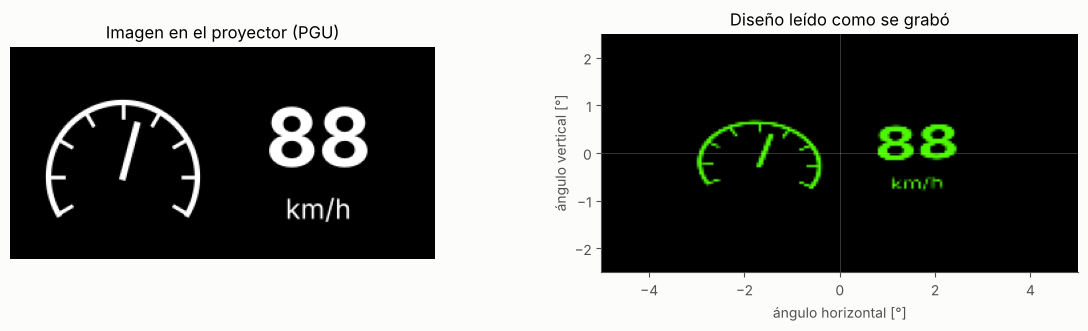

In [ ]:
# Ejemplo: el diseño visto por el conductor (ojo centrado, enfocando a 2 m, pupila de 4 mm)
OJO = dict(x=0.0, y=0.0, z=Z_OJO, enfoque=2.0, pupila=4e-3)
vista = ver_como_conductor(IMAGENES['velocimetro'], hoe, 532e-9, PROYECTOR, OJO)
mostrar_vista(IMAGENES['velocimetro'], vista, 532e-9, titulo='Diseño leído como se grabó')

In [ ]:
def lab_imagen(imagen, lambda_nm, angulo, colimado, distancia_m, contraccion_espesor_pct, contraccion_plano_pct,
               ojo_x_cm, ojo_y_cm, enfoque_m, pupila_mm, bragg):
    h = copy.copy(hoe)
    h.contraccion_plano = contraccion_plano_pct / 100
    h.contraccion_espesor = contraccion_espesor_pct / 100
    proy = dict(theta=angulo, distancia=None if colimado else distancia_m, fov=PROYECTOR['fov'])
    ojo = dict(x=ojo_x_cm / 100, y=ojo_y_cm / 100, z=Z_OJO, enfoque=enfoque_m, pupila=pupila_mm / 1000)
    vista = ver_como_conductor(IMAGENES[imagen], h, lambda_nm * 1e-9, proy, ojo, bragg=bragg)
    mostrar_vista(IMAGENES[imagen], vista, lambda_nm * 1e-9,
                  titulo=f'Lo que ve el conductor (enfocando a {enfoque_m:.2f} m)')

S = dict(style=ESTILO, continuous_update=False)
interact(lab_imagen,
         imagen=w.Dropdown(options=list(IMAGENES), value='velocimetro', description='imagen', style=ESTILO),
         lambda_nm=w.FloatSlider(value=532, min=450, max=680, step=1, description='λ lectura [nm]', **S),
         angulo=w.FloatSlider(value=45, min=35, max=55, step=0.5, description='ángulo proyector [°]', **S),
         colimado=w.Checkbox(value=True, description='proyector colimado'),
         distancia_m=w.FloatSlider(value=0.40, min=0.15, max=2.0, step=0.05, description='distancia proyector [m]', **S),
         contraccion_espesor_pct=w.FloatSlider(value=0, min=0, max=4, step=0.1, description='contracción espesor [%]', **S),
         contraccion_plano_pct=w.FloatSlider(value=0, min=-2, max=2, step=0.1, description='contracción plano [%]', **S),
         ojo_x_cm=w.FloatSlider(value=0, min=-5, max=5, step=0.1, description='ojo horizontal [cm]', **S),
         ojo_y_cm=w.FloatSlider(value=0, min=-5, max=5, step=0.1, description='ojo vertical [cm]', **S),
         enfoque_m=w.FloatSlider(value=2.0, min=0.5, max=4.0, step=0.05, description='ojo enfoca a [m]', **S),
         pupila_mm=w.FloatSlider(value=4, min=2, max=8, step=0.5, description='pupila [mm]', **S),
         bragg=w.Checkbox(value=True, description='incluir eficiencia de Bragg'));

interactive(children=(Dropdown(description='imagen', options=('velocimetro', 'rejilla', 'flecha'), style=Descr…

## 🌊 Lab 3 — Óptica de ondas (numpy · GPU con CuPy · HoloPy)

Los rayos no ven la difracción: con rayos, un HOE perfecto da un punto perfecto. Con ondas, la mancha mide aproximadamente `λ·d / lado`. Aquí se simula el campo de luz sobre un **parche cuadrado** del HOE (lo que ve una pupila o un poco más) y se propaga "hacia atrás" para ver dónde se enfoca.

**Pasos**
1. Fase que sale del HOE: `φ = φ_C + φ_H`, con `φ_H = φ_O − φ_R` (Ec. 1). Es la misma regla de la rejilla, pero escrita en fases.
2. Se le quita la **inclinación promedio** (si lees con otra λ, el haz sale un poco ladeado). Así la ventana no tiene que ser enorme. Solo mueve la imagen de lado, y eso ya lo ves en los Labs 1 y 2.
3. **Espectro angular** (el método de `holopy.propagate`): FFT → multiplicar por `exp(−i·kz·d)` → FFT inversa. Con `d > 0` se va hacia atrás del vidrio, igual que en HoloPy.
4. Se barre la distancia `d` y se busca dónde la luz queda más concentrada.

**GPU.** La función `preparar_propagacion` recibe `xp`: con `xp = numpy` corre en CPU; con `xp = cupy` el **mismo código** corre en tu tarjeta NVIDIA. CuPy copia la API de numpy.

**HoloPy.** Si está instalado, el motor `'holopy'` usa sus funciones. `hp.propagate()` falla con versiones recientes de `xarray`; en ese caso se usan sus piezas internas (`fft`, `trans_func`). HoloPy arma su malla de frecuencias con un pequeño error de escala, por lo que su foco sale unos mm antes.

In [ ]:
def fase_en_hoe(fuente, X, Y, lam):
    '''Fase de una onda en el plano del HOE (relativa al centro), sobre mallas X, Y.'''
    k = 2 * np.pi / lam
    if fuente['tipo'] == 'plana':
        d = fuente['dir']
        return k * (d[0] * X + d[1] * Y)
    px, py, pz = fuente['pos']
    return k * (np.sqrt((X - px)**2 + (Y - py)**2 + pz**2) - np.sqrt(px**2 + py**2 + pz**2))


def fuente_del_proyector(proyector):
    '''El píxel central del proyector como onda: plana si es colimado, puntual si no.'''
    if proyector['distancia'] is None:
        return fuente_plana(proyector['theta'])
    eje, _, _ = ejes_proyector(proyector)
    return fuente_puntual(*(-proyector['distancia'] * eje))


def campo_en_hoe(hoe, lam, proyector, lado=8e-3, N_max=4096):
    '''Campo del orden útil sobre un parche de 'lado' × 'lado' en el centro del HOE.'''
    def fase(X, Y):
        s = 1 - hoe.contraccion_plano
        fase_H = fase_en_hoe(hoe.O, X / s, Y / s, hoe.lam) - fase_en_hoe(hoe.R, X / s, Y / s, hoe.lam)   # φ_O − φ_R
        return fase_en_hoe(fuente_del_proyector(proyector), X, Y, lam) + fase_H                          # φ_C + φ_H
    # inclinación promedio (pendiente de la fase en x y en y) → se quita
    h = lado / 2
    fx0 = (fase(h, 0.0) - fase(-h, 0.0)) / (2 * h)
    fy0 = (fase(0.0, h) - fase(0.0, -h)) / (2 * h)
    N = 1024
    while True:
        dx = lado / (N / 2)                                  # el parche ocupa la mitad de la ventana
        x = (np.arange(N) - N // 2) * dx
        X, Y = np.meshgrid(x, x, indexing='ij')
        F = fase(X, Y) - fx0 * X - fy0 * Y
        apertura = (np.abs(X) <= h) & (np.abs(Y) <= h)
        gx, gy = np.gradient(F, dx)
        ciclos_por_pixel = np.max(np.hypot(gx, gy)[apertura]) / (2 * np.pi) * dx
        if ciclos_por_pixel <= 0.4 or N >= N_max:            # Nyquist (0.5) con margen
            break
        N = min(N_max, sfft.next_fast_len(int(np.ceil(N * ciclos_por_pixel / 0.4))))
    inclinacion_mrad = 1e3 * np.hypot(fx0, fy0) / (2 * np.pi / lam)       # ángulo del haz quitado
    return x, dx, np.where(apertura, np.exp(1j * F), 0), inclinacion_mrad

In [ ]:
def preparar_propagacion(U, dx, lam, xp=np):
    '''Espectro angular. Regresa una función propagar(d) que da el campo a una distancia d.
    xp = numpy (CPU) o cupy (GPU): el código es el mismo.'''
    N = U.shape[0]
    U_hat = xp.fft.fft2(xp.asarray(U))                       # 1) descomponer en ondas planas
    f = xp.fft.fftfreq(N, dx)
    f2 = f[:, None]**2 + f[None, :]**2
    arg = 1 - lam**2 * f2
    km1 = xp.where(arg > 0, -lam**2 * f2 / (1 + xp.sqrt(xp.clip(arg, 0, None))), 0.0)   # kz/k − 1, estable
    viaja = arg > 0                                          # las demás son evanescentes

    def propagar(d):
        H = xp.exp(-2j * np.pi * d / lam * km1)              # 2) cada onda plana avanza su fase
        f_lim = 1 / (lam * np.sqrt((2 * d / (N * dx))**2 + 1))   # filtro anti-aliasing (Matsushima 2009)
        banda = xp.abs(f) < f_lim
        return xp.fft.ifft2(U_hat * H * (viaja & banda[:, None] & banda[None, :]))   # 3) volver a sumar
    return propagar


def preparar_propagacion_holopy(U, dx, lam):
    '''Lo mismo, pero con HoloPy.'''
    import holopy as hp
    from holopy.core.metadata import data_grid
    datos = data_grid(U, spacing=dx, medium_index=1.0, illum_wavelen=lam)   # campo + metadatos
    try:
        hp.propagate(datos, 0.1)                             # la forma "oficial"
        return lambda d: np.asarray(hp.propagate(datos, d)).squeeze()
    except TypeError:                                        # falla con xarray reciente
        from holopy.core.process import fft, ifft
        from holopy.propagation.convolution_propagation import trans_func
        F = fft(datos).squeeze('z')
        return lambda d: np.asarray(ifft(F * trans_func(datos, d, lam))).squeeze()


def motores_disponibles():
    motores = ['numpy']
    try:
        import cupy
        cupy.cuda.runtime.getDeviceCount()
        motores.append('cupy')
    except Exception:
        pass
    try:
        import holopy
        from holopy.core.metadata import data_grid
        motores.append('holopy')
    except Exception:
        pass
    return motores


def preparar(motor, U, dx, lam):
    if motor == 'cupy':
        import cupy as cp
        return preparar_propagacion(U, dx, lam, xp=cp), cp
    if motor == 'holopy':
        return preparar_propagacion_holopy(U, dx, lam), np
    return preparar_propagacion(U, dx, lam, xp=np), np


def a_numpy(a):
    return a.get() if hasattr(a, 'get') else np.asarray(a)   # trae de la GPU si hace falta


print('Motores disponibles en esta computadora:', motores_disponibles())

Motores disponibles en esta computadora: ['numpy', 'holopy']


In [ ]:
def curva_de_enfoque(propagar, xp, lam, lado):
    '''Barre la distancia detrás del vidrio y mide qué tan concentrada está la luz (pico / energía).'''
    def nitidez(d):
        I = xp.abs(propagar(d))**2
        return float(I.max() / I.sum())
    ds = np.geomspace(0.15, 3.0, 30)                        # barrido grueso
    m = np.array([nitidez(d) for d in ds])
    d0 = ds[np.argmax(m)]
    prof = lam / (2 * (lado / 2 / d0)**2)                   # profundidad de foco aproximada
    ancho = max(2 * prof, 0.6 * d0 * (ds[1] / ds[0] - 1))
    df = np.linspace(d0 - ancho, d0 + ancho, 31)            # barrido fino
    mf = np.array([nitidez(d) for d in df])
    orden = np.argsort(np.r_[ds, df])
    return np.r_[ds, df][orden], np.r_[m, mf][orden], df[np.argmax(mf)], prof


def laboratorio_ondas(hoe, lam, proyector, lado=8e-3, motor='numpy', guardar=None):
    t0 = time.time()
    x, dx, U, incl = campo_en_hoe(hoe, lam, proyector, lado)
    propagar, xp = preparar(motor, U, dx, lam)
    ds, m, d_mejor, prof = curva_de_enfoque(propagar, xp, lam, lado)
    I = np.abs(a_numpy(propagar(d_mejor)))**2
    print(f'motor {motor}: malla {len(x)}×{len(x)}, paso {dx * 1e6:.1f} µm, '
          f'inclinación quitada {incl:.2f} mrad, {time.time() - t0:.1f} s')

    fig, (a, b, c) = plt.subplots(1, 3, figsize=(13, 3.9), gridspec_kw={'width_ratios': [1, 1.4, 1]})
    k = np.abs(x) <= lado / 2
    paso = max(1, k.sum() // 500)
    a.imshow(np.angle(U[np.ix_(k, k)][::paso, ::paso]).T, origin='lower', cmap='twilight',
             extent=[-lado / 2 * 1e3, lado / 2 * 1e3] * 2)
    a.set_title('Fase que sale del HOE\n(sin la inclinación promedio)', fontsize=10)
    a.set_xlabel('x [mm]'); a.set_ylabel('y [mm]')

    v = (ds > d_mejor - 8 * prof) & (ds < d_mejor + 8 * prof)
    b.plot(ds[v] - Z_OJO, m[v] / m.max(), color=AZUL, marker='o', ms=3)
    b.axvline(Z_IMAGEN - Z_OJO, color=TINTA2, ls=':', lw=1)
    b.text(Z_IMAGEN - Z_OJO, 0.98, ' objetivo', color=TINTA2, fontsize=8, va='top', transform=b.get_xaxis_transform())
    b.set_xlabel('distancia del ojo [m]'); b.set_ylabel('concentración de la luz (normalizada)')
    b.set_title('¿Dónde se enfoca?', fontsize=10)
    b.grid(True, color=REJILLA)

    i, j = np.unravel_index(np.argmax(I), I.shape)
    r = int(np.ceil(4 * lam * d_mejor / lado / dx))
    sub = I[max(i - r, 0):i + r + 1, max(j - r, 0):j + r + 1]
    c.imshow(sub.T / sub.max(), origin='lower', cmap='Blues', interpolation='bilinear',
             extent=[-r * dx * 1e6, r * dx * 1e6] * 2)
    c.set_title(f'Mancha en el mejor foco\n({d_mejor - Z_OJO:.3f} m del ojo)', fontsize=10)
    c.set_xlabel('x [µm]'); c.set_ylabel('y [µm]')
    fig.tight_layout()
    if guardar:
        fig.savefig(guardar, dpi=150, bbox_inches='tight')
    plt.show()

motor numpy: malla 1024×1024, paso 15.6 µm, inclinación quitada 0.00 mrad, 5.9 s


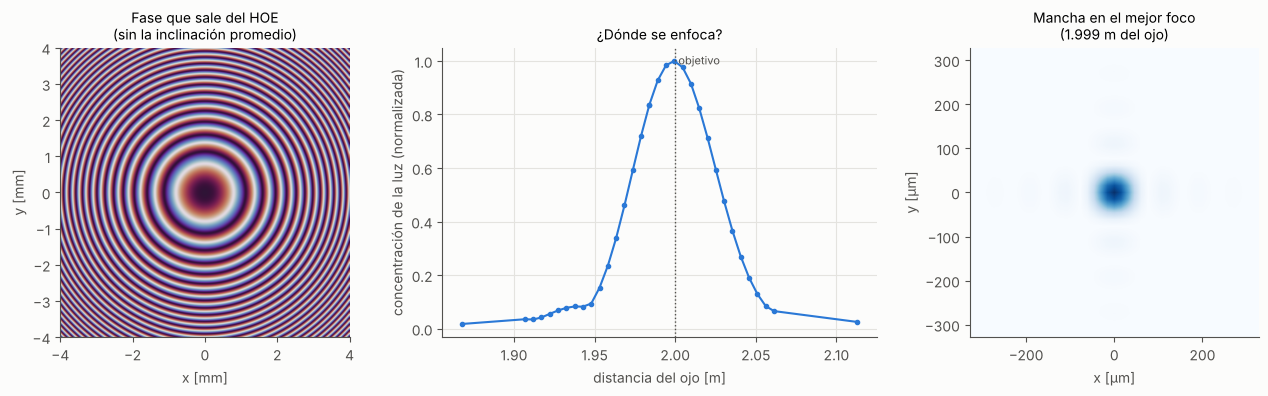

In [ ]:
# Ejemplo: el diseño, con un parche de 8 mm
laboratorio_ondas(hoe, 532e-9, PROYECTOR, lado=8e-3, motor='numpy')

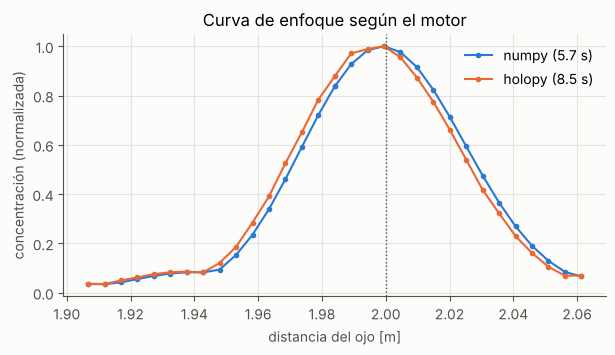

In [ ]:
# Comparación de motores: la misma física con numpy y (si lo tienes) con HoloPy o la GPU
x, dx, U, _ = campo_en_hoe(hoe, 532e-9, PROYECTOR, 8e-3)
plt.figure(figsize=(7, 3.4))
for motor, color in zip(motores_disponibles(), [AZUL, NARANJA, AQUA]):
    t0 = time.time()
    propagar, xp = preparar(motor, U, dx, 532e-9)
    ds, m, d_mejor, prof = curva_de_enfoque(propagar, xp, 532e-9, 8e-3)
    v = np.abs(ds - Z_IMAGEN) < 0.1
    plt.plot(ds[v] - Z_OJO, m[v] / m.max(), color=color, marker='o', ms=3,
             label=f'{motor} ({time.time() - t0:.1f} s)')
plt.axvline(Z_IMAGEN - Z_OJO, color=TINTA2, ls=':', lw=1)
plt.xlabel('distancia del ojo [m]'); plt.ylabel('concentración (normalizada)')
plt.legend(); plt.grid(True, color=REJILLA); plt.title('Curva de enfoque según el motor')
plt.show()

In [ ]:
# Para jugar. Mueve los controles y aprieta "Run Interact" (aquí cada cálculo tarda unos segundos)
def lab_ondas(motor, lambda_nm, angulo, colimado, distancia_m, contraccion_plano_pct, lado_mm):
    h = copy.copy(hoe)
    h.contraccion_plano = contraccion_plano_pct / 100
    proy = dict(theta=angulo, distancia=None if colimado else distancia_m, fov=PROYECTOR['fov'])
    laboratorio_ondas(h, lambda_nm * 1e-9, proy, lado=lado_mm / 1000, motor=motor)

interact_manual(lab_ondas,
                motor=w.Dropdown(options=motores_disponibles(), value='numpy', description='motor', style=ESTILO),
                lambda_nm=w.FloatSlider(value=532, min=500, max=570, step=1, description='λ lectura [nm]', style=ESTILO),
                angulo=w.FloatSlider(value=45, min=40, max=50, step=0.5, description='ángulo proyector [°]', style=ESTILO),
                colimado=w.Checkbox(value=True, description='proyector colimado'),
                distancia_m=w.FloatSlider(value=0.40, min=0.2, max=2.0, step=0.05, description='distancia proyector [m]', style=ESTILO),
                contraccion_plano_pct=w.FloatSlider(value=0, min=-2, max=2, step=0.1, description='contracción plano [%]', style=ESTILO),
                lado_mm=w.FloatSlider(value=8, min=2, max=15, step=0.5, description='lado del parche [mm]', style=ESTILO));

interactive(children=(Dropdown(description='motor', options=('numpy', 'holopy'), style=DescriptionStyle(descri…

## 🛠️ Construye lo tuyo

Todo sale de tres objetos: un **`HOE`** (cómo lo grabaste), un **`proyector`** (cómo lo iluminas) y un **`ojo`** (desde dónde lo ves). Cambia cualquiera y llama a las funciones de los labs.

**Ejemplo A — Otro diseño: HOE grabado con el proyector cerca (lente convergente).** En vez de grabar con una onda plana, la referencia sale de un punto a 0.4 m, donde estará el proyector. Compara qué pasa si lo lees con ese proyector… y si lo lees con uno colimado.

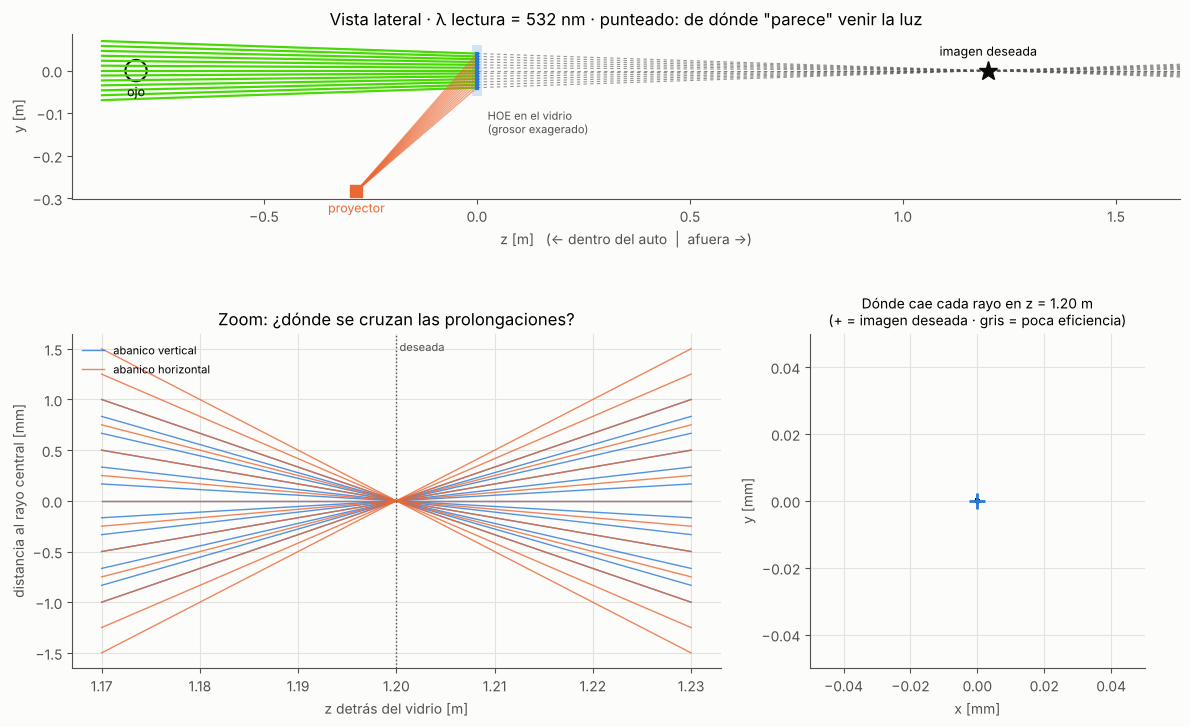

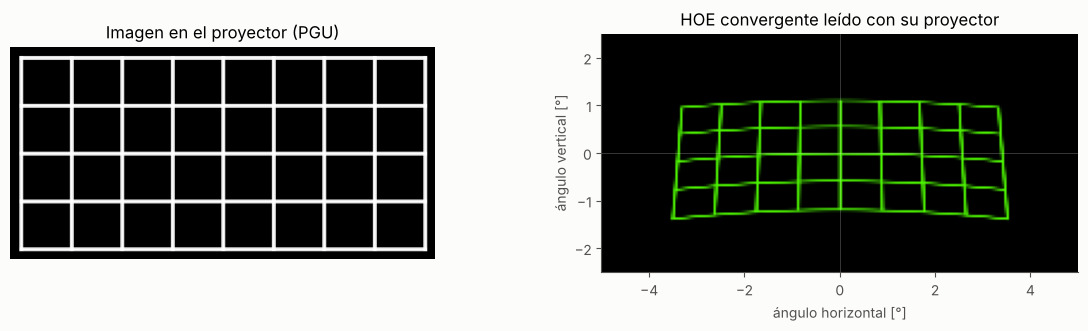

In [ ]:
proy_cerca = dict(theta=45, distancia=0.40, fov=(12, 6))
hoe_conv = HOE(lam=532e-9,
               referencia=fuente_del_proyector(proy_cerca),      # onda esférica desde el proyector
               objeto=fuente_puntual(0, 0, Z_IMAGEN))

dibujar_rayos(hoe_conv, 532e-9, proy_cerca)
vista = ver_como_conductor(IMAGENES['rejilla'], hoe_conv, 532e-9, proy_cerca, OJO)
mostrar_vista(IMAGENES['rejilla'], vista, 532e-9, titulo='HOE convergente leído con su proyector')

**Ejemplo B — Tu imagen.** Guarda un PNG (fondo negro, dibujo claro) junto a este notebook y:
```python
IMAGENES['mia'] = cargar_imagen('mi_imagen.png')
vista = ver_como_conductor(IMAGENES['mia'], hoe, 532e-9, PROYECTOR, OJO)
mostrar_vista(IMAGENES['mia'], vista, 532e-9)
```
Vuelve a correr la celda de controles del Lab 2 y aparecerá en la lista.

**Ejemplo C — Los dos ojos.** Llama `ver_como_conductor` con `OJO` en `x = −0.032` y en `x = +0.032` y resta las dos vistas: lo que no sea cero es lo que cada ojo ve distinto.

**Ideas para seguir construyendo**
- **Parabrisas curvo:** en `ver_como_conductor`, el paso 2 cruza el rayo con el plano `z = 0`. Cámbialo por una superficie curva y evalúa `hoe.K` en coordenadas de esa superficie.
- **Color (RGB):** graba tres HOEs (por ejemplo 460, 532 y 633 nm), calcula una vista para cada uno y súmalas con su color.
- **Diseño inverso:** busca el ángulo de lectura que compensa una contracción dada.

**Referencias**
- H. Kogelnik, *Coupled wave theory for thick hologram gratings*, Bell Syst. Tech. J. 48, 2909 (1969).
- K. Matsushima y T. Shimobaba, *Band-limited angular spectrum method*, Opt. Express 17, 19662 (2009).
- HoloPy: https://holopy.readthedocs.io